# Task 2: Real Estate Housing Price Prediction (Ridge & Lasso Regression)
**Dataset:** California Housing (`housing.csv`, 20,640 districts)  
**Goal:** Predict `median_house_value` and compare OLS, Ridge (L2) and Lasso (L1) using RMSE, MAE and R².

**Pipeline:** load → impute → feature engineering → correlation / multicollinearity → scale + encode → GridSearchCV → evaluation plots.

**Requirements:** `pip install pandas numpy matplotlib seaborn scikit-learn scipy statsmodels`

In [1]:
# ---- Imports ----
import numpy as np                      # numerical arrays and maths
import pandas as pd                     # tabular data handling (DataFrames)
import matplotlib.pyplot as plt         # base plotting library
import seaborn as sns                   # nicer statistical plots (heatmaps, histograms)
from scipy import stats                 # used for the Q-Q plot of residuals

from sklearn.model_selection import train_test_split, GridSearchCV   # splitting + hyperparameter search
from sklearn.pipeline import Pipeline                                # chains preprocessing + model
from sklearn.compose import ColumnTransformer                        # applies different steps to different columns
from sklearn.impute import SimpleImputer                             # fills missing values
from sklearn.preprocessing import StandardScaler, OneHotEncoder      # scaling + categorical encoding
from sklearn.linear_model import LinearRegression, Ridge, Lasso      # the three models we compare
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score  # evaluation metrics
import warnings; warnings.filterwarnings("ignore")                   # keep the output clean

sns.set_theme(style="whitegrid")        # consistent plot style
RANDOM_STATE = 42                       # fixed seed so results are reproducible
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"


## 1. Load the dataset
We read the CSV straight from GitHub. If there is no internet, the notebook falls back to a local `housing.csv` placed in the same folder.

In [2]:
try:
    df = pd.read_csv(URL)               # try downloading from the URL first
except Exception:
    df = pd.read_csv("housing.csv")     # fallback: local copy next to the notebook
print(df.shape)                         # (rows, columns)
df.head()                               # preview the first 5 rows

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
# Summary statistics (count, mean, std, min, quartiles, max) for every numeric column.
# Useful for spotting skew, outliers and the missing count in total_bedrooms.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


## 2. Missing values

In [4]:
# Count nulls per column and show only the columns that actually have missing values
missing = df.isna().sum()
print(missing[missing > 0])
print(f"\nMissing share of total_bedrooms: {df['total_bedrooms'].isna().mean():.2%}")

total_bedrooms    207
dtype: int64

Missing share of total_bedrooms: 1.00%


Only `total_bedrooms` has nulls (207 rows). We use **median imputation**, which is robust to the heavy right skew in this column. 
The imputer lives **inside the pipeline**, so its median is learned from training data only (no data leakage).

## 3. Feature engineering
Raw counts like `total_rooms` depend on district size, so we create per-household ratios, plus interaction features (products of two variables) that let a linear model capture "effect of A depends on B".

In [5]:
def add_features(d):
    d = d.copy()                                                  # never modify the original DataFrame
    # --- ratio features (size-independent) ---
    d["rooms_per_household"]      = d["total_rooms"] / d["households"]        # average home size
    d["bedrooms_per_room"]        = d["total_bedrooms"] / d["total_rooms"]    # bedroom share of rooms
    d["population_per_household"] = d["population"] / d["households"]        # average household size
    # --- interaction features (product of two variables) ---
    d["income_x_rooms_per_hh"]    = d["median_income"] * d["rooms_per_household"]  # rich AND spacious
    d["income_x_age"]             = d["median_income"] * d["housing_median_age"]   # income effect varies with building age
    return d

df_fe = add_features(df)
# Inspect the new columns (NaN in bedrooms_per_room comes from the missing total_bedrooms; handled later by the imputer)
df_fe[["rooms_per_household","bedrooms_per_room","population_per_household",
       "income_x_rooms_per_hh","income_x_age"]].describe().T

,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
bedrooms_per_room,20433.0,0.213039,0.057983,0.100000,0.175427,0.203162,0.239821,1.000000
population_per_household,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
income_x_rooms_per_hh,20640.0,22.550365,17.923133,0.856971,11.686844,18.021764,27.864426,612.966667
income_x_age,20640.0,108.008027,74.386418,1.625000,57.997425,92.502950,140.104900,780.005200


Note: the target is **capped at \$500,001** in this dataset (censored values), which limits how well any linear model can fit the top end. 
We model the target in units of \$100k for numerical stability and convert back to dollars when reporting RMSE/MAE.

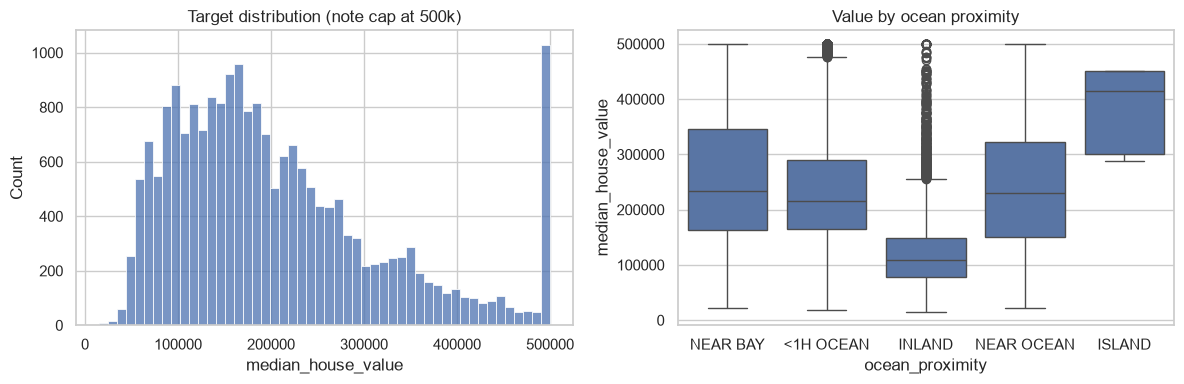

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# Left: distribution of the target; the spike at the right edge is the $500k cap
sns.histplot(df["median_house_value"], bins=50, ax=ax[0]); ax[0].set_title("Target distribution (note cap at 500k)")
# Right: house value by the categorical feature, shows ocean proximity matters
sns.boxplot(x="ocean_proximity", y="median_house_value", data=df, ax=ax[1]); ax[1].set_title("Value by ocean proximity")
plt.tight_layout(); plt.show()

## 4. Correlation heatmap & multicollinearity

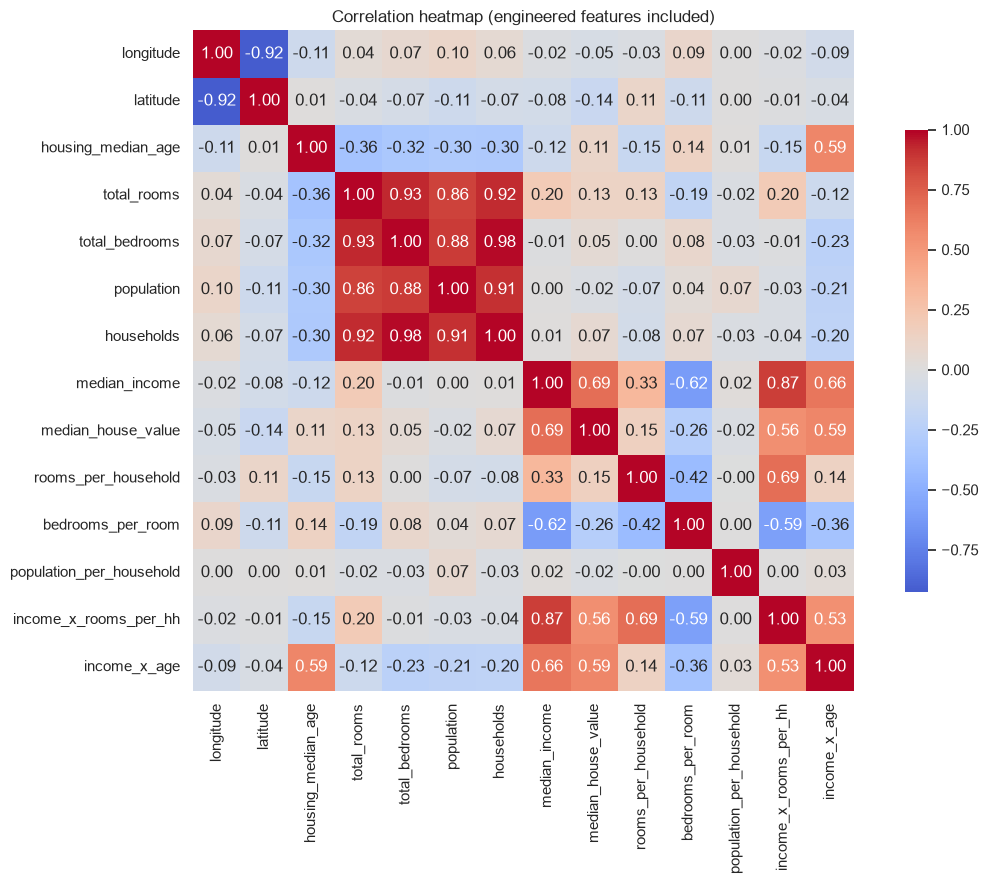

Correlation with median_house_value:
median_income               0.688
income_x_age                0.589
income_x_rooms_per_hh       0.555
rooms_per_household         0.152
total_rooms                 0.134
housing_median_age          0.106
households                  0.066
total_bedrooms              0.050
population_per_household   -0.024
population                 -0.025
longitude                  -0.046
latitude                   -0.144
bedrooms_per_room          -0.256
Name: median_house_value, dtype: float64


In [7]:
# Pearson correlation between all numeric columns (engineered ones included)
num_cols = df_fe.select_dtypes("number").columns
corr = df_fe[num_cols].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation heatmap (engineered features included)")
plt.tight_layout(); plt.show()

# Which features relate most strongly to the target?
print("Correlation with median_house_value:")
print(corr["median_house_value"].drop("median_house_value").sort_values(ascending=False).round(3))

In [8]:
# Variance Inflation Factor (VIF): how well each feature is predicted by the others.
# Rule of thumb: VIF > 10 = serious multicollinearity.
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_vif = df_fe.drop(columns=["median_house_value","ocean_proximity"])   # numeric predictors only
X_vif = X_vif.fillna(X_vif.median())                                   # VIF can't handle NaN
X_vif = (X_vif - X_vif.mean()) / X_vif.std()                           # standardize
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
                index=X_vif.columns).sort_values(ascending=False)
vif.round(1).to_frame("VIF")

,VIF
total_bedrooms,34.4
households,34.1
median_income,20.0
income_x_rooms_per_hh,18.4
total_rooms,17.9
latitude,9.6
longitude,9.2
income_x_age,9.2
population,6.7
housing_median_age,5.5


**Finding:** `total_rooms`, `total_bedrooms`, `population`, `households` are strongly collinear, and the interaction terms add more. 
OLS coefficients become unstable under this; **Ridge** shrinks correlated coefficients together and **Lasso** drops redundant ones, which is exactly why we compare them.

## 5. Train/test split, scaling and encoding
Regularized models penalize coefficient size, so features must be on the same scale (StandardScaler). Categorical text must be turned into numbers (OneHotEncoder).

In [9]:
y = df_fe["median_house_value"] / 1e5          # target in units of $100k (keeps alpha values readable)
X = df_fe.drop(columns="median_house_value")    # all remaining columns are features

# 80% train / 20% test; random_state makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

cat_cols = ["ocean_proximity"]                              # categorical column
num_cols = [c for c in X.columns if c not in cat_cols]      # everything else is numeric

# Preprocessing: different treatment for numeric vs categorical columns
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),   # fill nulls with the training median
                      ("scale",  StandardScaler())]), num_cols),      # mean 0, std 1
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),        # one 0/1 column per category
])
print(X_train.shape, X_test.shape)

(16512, 14) (4128, 14)


## 6. Models: OLS baseline, Ridge and Lasso with GridSearchCV
- **OLS:** no penalty (baseline).
- **Ridge (L2):** penalizes squared coefficients → shrinks them, rarely to zero.
- **Lasso (L1):** penalizes absolute coefficients → can shrink some exactly to zero (feature selection).
`alpha` controls penalty strength; GridSearchCV tries many values with 5-fold cross-validation and keeps the best.

In [10]:
# Helper: bundle preprocessing + model so every step is fitted only on training folds (no leakage)
def make_pipe(model): return Pipeline([("prep", preprocess), ("model", model)])

# --- OLS baseline ---
ols = make_pipe(LinearRegression()).fit(X_train, y_train)

# --- Ridge: search 29 alpha values from 1e-4 to 1e3, scored by RMSE across 5 folds ---
ridge_gs = GridSearchCV(make_pipe(Ridge(random_state=RANDOM_STATE)),
                        {"model__alpha": np.logspace(-4, 3, 29)},
                        cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)

# --- Lasso: search 25 alpha values from 1e-6 to 1; max_iter raised so it converges ---
lasso_gs = GridSearchCV(make_pipe(Lasso(max_iter=20000, random_state=RANDOM_STATE)),
                        {"model__alpha": np.logspace(-6, 0, 25)},
                        cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)

print("Best Ridge alpha:", ridge_gs.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_gs.best_params_["model__alpha"])

Best Ridge alpha: 1.0
Best Lasso alpha: 5.623413251903491e-05


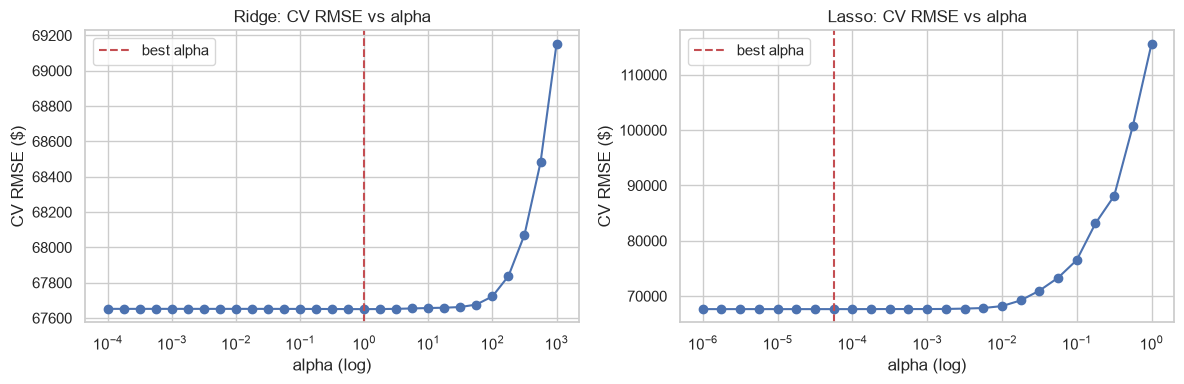

In [11]:
# Plot CV error against alpha: the dip shows the best penalty strength
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, gs, name in [(ax[0], ridge_gs, "Ridge"), (ax[1], lasso_gs, "Lasso")]:
    alphas = gs.cv_results_["param_model__alpha"].data.astype(float)   # tried alpha values
    rmse = -gs.cv_results_["mean_test_score"] * 1e5                    # flip sign, convert to dollars
    a.semilogx(alphas, rmse, marker="o")                               # log x-axis because alpha spans orders of magnitude
    a.axvline(gs.best_params_["model__alpha"], color="r", ls="--", label="best alpha")
    a.set(title=f"{name}: CV RMSE vs alpha", xlabel="alpha (log)", ylabel="CV RMSE ($)"); a.legend()
plt.tight_layout(); plt.show()

## 7. Model comparison (RMSE, MAE, R²)

In [12]:
models = {"OLS": ols, "Ridge (L2)": ridge_gs.best_estimator_, "Lasso (L1)": lasso_gs.best_estimator_}
rows, preds = [], {}
for name, m in models.items():
    for split, Xs, ys in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        p = m.predict(Xs)                                   # predictions (in $100k units)
        if split == "Test": preds[name] = p                 # keep test predictions for the plots below
        rows.append({"Model": name, "Split": split,
                     "RMSE ($)": np.sqrt(mean_squared_error(ys, p)) * 1e5,   # penalizes large errors more
                     "MAE ($)":  mean_absolute_error(ys, p) * 1e5,           # average absolute error
                     "R²":       r2_score(ys, p)})                            # share of variance explained
results = pd.DataFrame(rows)
results_test = results[results.Split == "Test"].set_index("Model").drop(columns="Split")
display(results.round(4).set_index(["Model", "Split"]))    # train vs test (checks over/underfitting)
results_test.round(4)                                      # test-only summary used for the final comparison

RMSE ($)     MAE ($)      R²
Model      Split                                
OLS        Train  67366.0691  48558.0864  0.6605
           Test   68845.0016  49458.6655  0.6383
Ridge (L2) Train  67367.0597  48558.1445  0.6605
           Test   68853.9028  49464.2259  0.6382
Lasso (L1) Train  67367.0745  48557.2235  0.6605
           Test   68853.8044  49462.0134  0.6382

,RMSE ($),MAE ($),R²
Model,,,
OLS,68845.0016,49458.6655,0.6383
Ridge (L2),68853.9028,49464.2259,0.6382
Lasso (L1),68853.8044,49462.0134,0.6382


,OLS,Ridge (L2),Lasso (L1)
longitude,-0.564,-0.563,-0.563
latitude,-0.568,-0.567,-0.567
housing_median_age,0.061,0.060,0.060
total_rooms,0.107,0.107,0.107
total_bedrooms,0.029,0.030,0.030
population,-0.454,-0.454,-0.454
households,0.371,0.370,0.370
median_income,0.813,0.812,0.811
rooms_per_household,0.135,0.134,0.134
bedrooms_per_room,0.188,0.187,0.187


Features zeroed out by Lasso: ['ocean_proximity_<1H OCEAN']


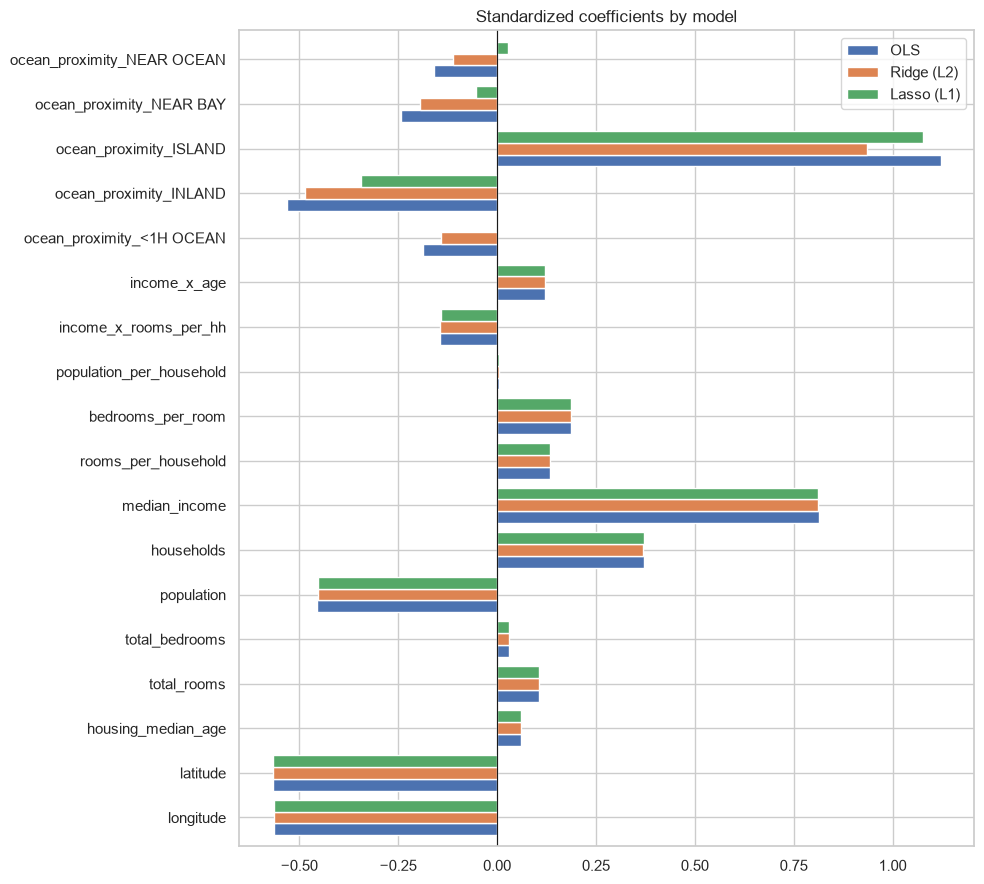

In [13]:
# Compare learned coefficients (on standardized features, so sizes are comparable)
feat_names = list(models["OLS"].named_steps["prep"].get_feature_names_out())
coef = pd.DataFrame({n: m.named_steps["model"].coef_ for n, m in models.items()}, index=feat_names)
coef.index = [i.split("__")[1] for i in coef.index]        # strip the 'num__'/'cat__' prefixes
display(coef.round(3))
# Lasso's feature selection: any coefficient exactly 0 was dropped
print("Features zeroed out by Lasso:", list(coef.index[coef["Lasso (L1)"] == 0]) or "none")

coef.plot.barh(figsize=(10, 9), width=0.8)
plt.title("Standardized coefficients by model"); plt.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()

## 8. Predicted vs actual
Points on the red diagonal are perfect predictions. Spread around it shows error; the flat column at the right is the \$500k cap.

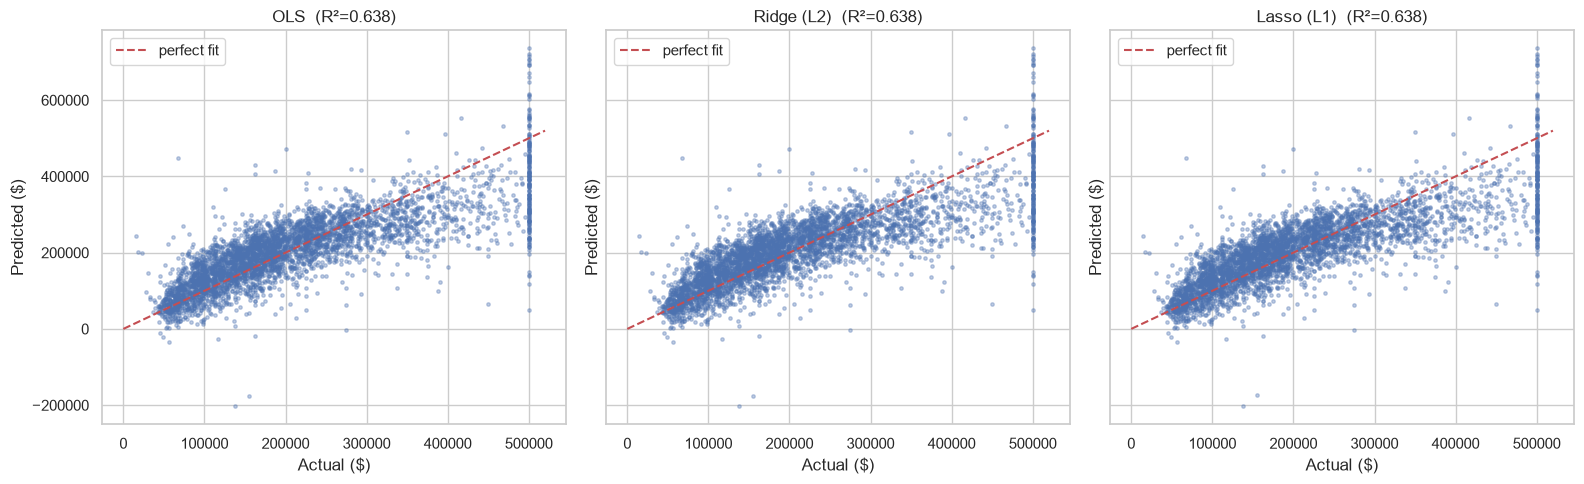

In [14]:
y_test_d = y_test * 1e5                                    # actual values in dollars
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test_d, p * 1e5, s=6, alpha=.35)          # each dot = one test district
    lim = [0, 520000]; ax.plot(lim, lim, "r--", label="perfect fit")
    ax.set(title=f"{name}  (R²={r2_score(y_test, p):.3f})", xlabel="Actual ($)", ylabel="Predicted ($)"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Residual analysis
Residual = actual − predicted. A good model has residuals centred on 0, roughly normal, and no pattern against the prediction.

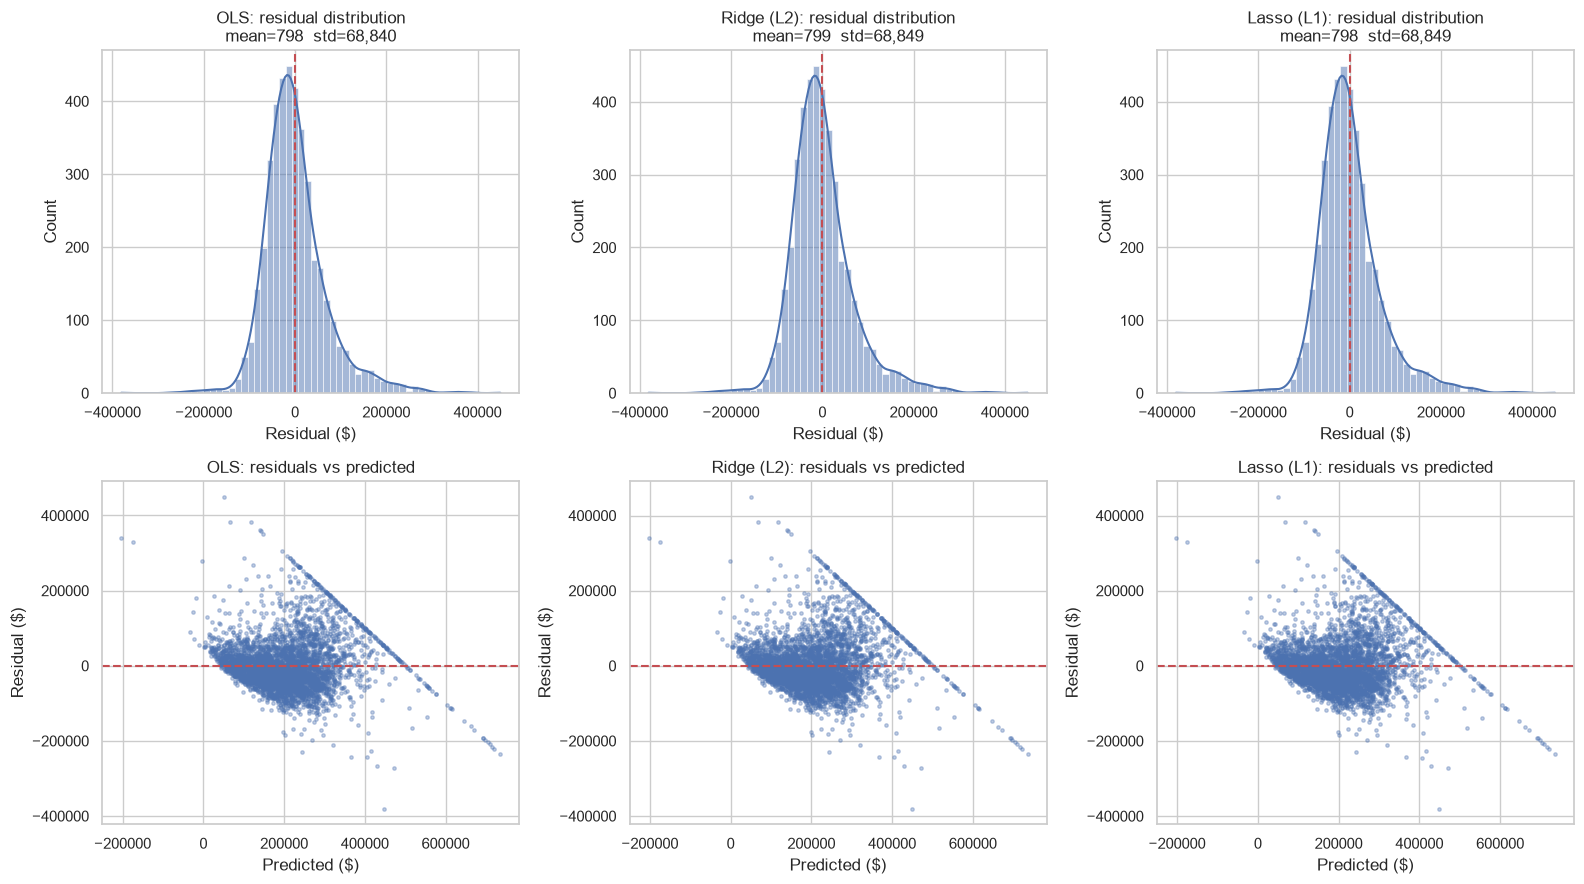

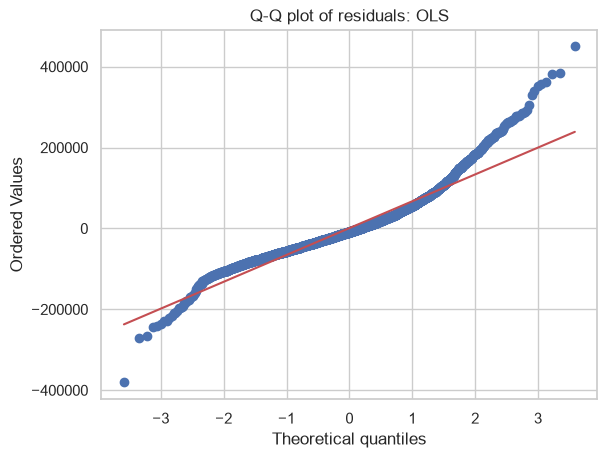

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, (name, p) in enumerate(preds.items()):
    resid = (y_test.values - p) * 1e5                      # residuals in dollars
    # Top row: residual distribution (should be a bell centred on 0)
    sns.histplot(resid, bins=60, kde=True, ax=axes[0, j])
    axes[0, j].axvline(0, color="r", ls="--")
    axes[0, j].set_title(f"{name}: residual distribution\nmean={resid.mean():,.0f}  std={resid.std():,.0f}")
    axes[0, j].set_xlabel("Residual ($)")
    # Bottom row: residuals vs predicted (a fan shape means heteroscedasticity)
    axes[1, j].scatter(p * 1e5, resid, s=6, alpha=.35)
    axes[1, j].axhline(0, color="r", ls="--")
    axes[1, j].set(title=f"{name}: residuals vs predicted", xlabel="Predicted ($)", ylabel="Residual ($)")
plt.tight_layout(); plt.show()

# Q-Q plot for the best model: points on the line = normally distributed residuals
best = results_test["RMSE ($)"].idxmin()
stats.probplot((y_test.values - preds[best]) * 1e5, dist="norm", plot=plt)
plt.title(f"Q-Q plot of residuals: {best}"); plt.show()

## 10. Conclusions

In [16]:
# Final summary table of test-set performance
best_r2 = results_test["R²"].idxmax()
print(f"Best test RMSE: {best}  |  Best test R²: {best_r2}\n")
print(results_test.round(3).to_string())

Best test RMSE: OLS  |  Best test R²: OLS

             RMSE ($)    MAE ($)     R²
Model                                  
OLS         68845.002  49458.665  0.638
Ridge (L2)  68853.903  49464.226  0.638
Lasso (L1)  68853.804  49462.013  0.638


**Key takeaways**
- **All three models perform almost identically** (test R² ≈ 0.64, RMSE ≈ \$69k, MAE ≈ \$49k). With ~16k training rows and only ~17 features, there is little variance for regularization to remove, so OLS is as good as Ridge/Lasso here. The best alphas are small (Ridge 1.0, Lasso ≈ 5e-5), meaning light regularization is preferred.
- **Multicollinearity:** VIFs show `total_bedrooms`, `households`, `total_rooms` and the income interaction terms are strongly collinear. Lasso responds by zeroing the redundant `ocean_proximity_<1H OCEAN` dummy; Ridge keeps every coefficient but shrinks them slightly.
- **Train vs test gap is small** (R² 0.66 vs 0.64), so the limit is **underfitting / model form**, not overfitting. That is why regularization cannot help much.
- **Residuals:** errors are right-skewed and fan out at higher predicted values (heteroscedasticity), with a visible band at the \$500k cap, so a linear model is missing non-linear and geographic structure.
- **Next steps:** log-transform the target, add geographic features (distance to coast or major cities), polynomial terms, or try tree-based models (Random Forest / Gradient Boosting).